# Phân tích khám phá dữ liệu Online Retail

## 1.2.3. EDA dữ liệu bán lẻ trực tuyến

### 1. Đọc dữ liệu

Dữ liệu được đọc từ file Online Retail.xlsx.
Mỗi dòng là một mục hàng trong hóa đơn; một hóa đơn có thể
gồm nhiều dòng.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

retail_data = pd.read_excel(
    "data/Online Retail.xlsx",
    sheet_name="Online Retail",
    engine="openpyxl"
)

print("Kích thước dữ liệu:", retail_data.shape)
display(retail_data.head())

Kích thước dữ liệu: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 2. Kiểm tra dữ liệu ban đầu

Kiểm tra kiểu dữ liệu, giá trị thiếu, dòng trùng, thời gian ghi nhận,
hóa đơn hủy và các giá trị số lượng hoặc đơn giá không dương.

In [2]:
print("Kiểu dữ liệu:")
print(retail_data.dtypes)

missing_summary = pd.DataFrame({
    "Số giá trị thiếu": retail_data.isna().sum(),
    "Tỷ lệ thiếu (%)": retail_data.isna().mean() * 100
})

print("\nGiá trị thiếu:")
display(missing_summary)

print("Số dòng trùng hoàn toàn:", retail_data.duplicated().sum())

print("\nThời gian bắt đầu:", retail_data["InvoiceDate"].min())
print("Thời gian kết thúc:", retail_data["InvoiceDate"].max())

# Nhận diện hóa đơn hủy bằng tiền tố C
cancel_mask = (
    retail_data["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

print("\nSố dòng thuộc hóa đơn hủy:", cancel_mask.sum())
print("Số hóa đơn hủy riêng biệt:",
      retail_data.loc[cancel_mask, "InvoiceNo"].nunique())

print("\nSố dòng Quantity < 0:", (retail_data["Quantity"] < 0).sum())
print("Số dòng Quantity = 0:", (retail_data["Quantity"] == 0).sum())
print("Số dòng UnitPrice < 0:", (retail_data["UnitPrice"] < 0).sum())
print("Số dòng UnitPrice = 0:", (retail_data["UnitPrice"] == 0).sum())

print("\nSố quốc gia:", retail_data["Country"].nunique())

Kiểu dữ liệu:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Giá trị thiếu:


,Số giá trị thiếu,Tỷ lệ thiếu (%)
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


Số dòng trùng hoàn toàn: 5268

Thời gian bắt đầu: 2010-12-01 08:26:00
Thời gian kết thúc: 2011-12-09 12:50:00

Số dòng thuộc hóa đơn hủy: 9288
Số hóa đơn hủy riêng biệt: 3836

Số dòng Quantity < 0: 10624
Số dòng Quantity = 0: 0
Số dòng UnitPrice < 0: 2
Số dòng UnitPrice = 0: 2515

Số quốc gia: 38


### 3. Chuẩn bị dữ liệu cho phân tích bán hàng

Loại các dòng trùng hoàn toàn, giữ lần xuất hiện đầu tiên.
Đây là giả định làm sạch nhằm tránh đếm lặp; dữ liệu không có
mã riêng cho từng dòng hàng để xác minh tuyệt đối.

Chọn các dòng không thuộc hóa đơn hủy, có Quantity > 0
và UnitPrice > 0.

Giữ các dòng thiếu CustomerID hoặc Description vì vẫn có thể
sử dụng cho phân tích giá trị bán hàng theo thời gian và quốc gia.

Giá trị dòng hàng = Quantity × UnitPrice.
Kết quả phân tích không bao gồm việc khấu trừ các giao dịch hủy.

In [3]:
# Tạo bản sao sau khi loại dòng trùng
retail_unique = retail_data.drop_duplicates().copy()

cancel_mask_unique = (
    retail_unique["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

sales_mask = (
    ~cancel_mask_unique
    & (retail_unique["Quantity"] > 0)
    & (retail_unique["UnitPrice"] > 0)
)

retail_sales = retail_unique.loc[sales_mask].copy()

# Chuẩn hóa mã hóa đơn và mã sản phẩm về dạng chuỗi
retail_sales["InvoiceNo"] = retail_sales["InvoiceNo"].astype("string")
retail_sales["StockCode"] = retail_sales["StockCode"].astype("string")

# Tính giá trị từng dòng hàng
retail_sales["SalesValue"] = (
    retail_sales["Quantity"] * retail_sales["UnitPrice"]
)

print("Số dòng ban đầu:", len(retail_data))
print("Số dòng trùng đã loại:", len(retail_data) - len(retail_unique))
print("Số dòng sau khi bỏ trùng:", len(retail_unique))
print("Số dòng bị loại bởi điều kiện bán hàng:",
      len(retail_unique) - len(retail_sales))
print("Số dòng dùng phân tích bán hàng:", len(retail_sales))

print("\nCustomerID còn thiếu:", retail_sales["CustomerID"].isna().sum())
print("Description còn thiếu:", retail_sales["Description"].isna().sum())

display(retail_sales.head())

Số dòng ban đầu: 541909
Số dòng trùng đã loại: 5268
Số dòng sau khi bỏ trùng: 536641
Số dòng bị loại bởi điều kiện bán hàng: 11763
Số dòng dùng phân tích bán hàng: 524878

CustomerID còn thiếu: 132186
Description còn thiếu: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


### 4. Tổng quan dữ liệu bán hàng

Tính số hóa đơn, số mã hàng, số khách hàng có mã định danh
và tổng giá trị các dòng bán hàng đã chọn.

Một hóa đơn có thể chứa nhiều dòng hàng.
Số khách hàng chỉ tính trên CustomerID không thiếu.
Tổng giá trị bán hàng chưa khấu trừ giao dịch hủy hoặc hoàn trả.

In [4]:
invoice_values = retail_sales.groupby("InvoiceNo")["SalesValue"].sum()

print("Số dòng hàng:", f"{len(retail_sales):,}")
print("Số hóa đơn:", f"{retail_sales['InvoiceNo'].nunique():,}")
print("Số mã hàng:", f"{retail_sales['StockCode'].nunique():,}")
print("Số khách hàng có mã:", f"{retail_sales['CustomerID'].nunique():,}")
print("Số quốc gia:", retail_sales["Country"].nunique())

print("\nTổng số lượng:", f"{retail_sales['Quantity'].sum():,}")
print("Tổng giá trị bán hàng:",
      f"{retail_sales['SalesValue'].sum():,.2f}")

print("\nGiá trị trung bình mỗi hóa đơn:",
      f"{invoice_values.mean():,.2f}")
print("Giá trị trung vị mỗi hóa đơn:",
      f"{invoice_values.median():,.2f}")

display(
    retail_sales[["Quantity", "UnitPrice", "SalesValue"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

Số dòng hàng: 524,878
Số hóa đơn: 19,960
Số mã hàng: 3,922
Số khách hàng có mã: 4,338
Số quốc gia: 38

Tổng số lượng: 5,572,420
Tổng giá trị bán hàng: 10,642,110.80

Giá trị trung bình mỗi hóa đơn: 533.17
Giá trị trung vị mỗi hóa đơn: 303.30


,count,mean,std,min,25%,50%,75%,95%,99%,max
Quantity,524878.0,10.616600,156.280031,1.000,1.00,4.00,11.00,30.00,100.00,80995.00
UnitPrice,524878.0,3.922573,36.093028,0.001,1.25,2.08,4.13,9.95,16.98,13541.33
SalesValue,524878.0,20.275399,271.693566,0.001,3.90,9.92,17.70,59.80,183.60,168469.60


### 5. Kiểm tra các dòng có giá trị lớn

Xem các dòng có số lượng, đơn giá và giá trị bán hàng lớn nhất.
Chưa loại bỏ các dòng này khi chưa xác minh nguyên nhân.

In [5]:
check_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "SalesValue"
]

print("5 dòng có số lượng lớn nhất:")
display(retail_sales.nlargest(5, "Quantity")[check_columns])

print("\n5 dòng có đơn giá lớn nhất:")
display(retail_sales.nlargest(5, "UnitPrice")[check_columns])

print("\n5 dòng có giá trị bán hàng lớn nhất:")
display(retail_sales.nlargest(5, "SalesValue")[check_columns])

5 dòng có số lượng lớn nhất:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,SalesValue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,168469.60
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,77183.60
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21,12901.0,1008.00
206121,554868,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00,0.72,13135.0,3096.00
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00,0.82,18087.0,3202.92



5 dòng có đơn giá lớn nhất:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,SalesValue
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,13541.33
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,11062.06
173382,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.75,16029.0,8142.75
297723,562955,DOT,DOTCOM POSTAGE,1,2011-08-11 10:14:00,4505.17,NaN,4505.17
268028,560373,M,Manual,1,2011-07-18 12:30:00,4287.63,NaN,4287.63



5 dòng có giá trị bán hàng lớn nhất:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,SalesValue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,168469.60
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,77183.60
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098.0,38970.00
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,13541.33
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,11062.06


### Kiểm tra giao dịch âm tương ứng với hai dòng lớn nhất

Đối chiếu trong dữ liệu gốc theo mã hàng, khách hàng,
đơn giá và số lượng có cùng độ lớn nhưng trái dấu.

Các dòng đối ứng tìm được giúp nhận diện khả năng hủy hoặc
hoàn trả; dữ liệu không có liên kết trực tiếp giữa các dòng hóa đơn.

In [6]:
largest_rows = retail_sales.nlargest(2, "Quantity")

for _, row in largest_rows.iterrows():
    matching_negative = retail_data.loc[
        (retail_data["StockCode"].astype("string") == row["StockCode"])
        & (retail_data["CustomerID"] == row["CustomerID"])
        & (retail_data["Quantity"] == -row["Quantity"])
        & (retail_data["UnitPrice"] == row["UnitPrice"])
    ].copy()

    matching_negative["SalesValue"] = (
        matching_negative["Quantity"] * matching_negative["UnitPrice"]
    )

    print(f"\nDòng bán cần kiểm tra: hóa đơn {row['InvoiceNo']}")
    print("Số dòng âm khớp điều kiện:", len(matching_negative))
    display(matching_negative[check_columns])


Dòng bán cần kiểm tra: hóa đơn 581483
Số dòng âm khớp điều kiện: 1


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,SalesValue
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,-168469.6



Dòng bán cần kiểm tra: hóa đơn 541431
Số dòng âm khớp điều kiện: 1


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,SalesValue
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,-77183.6


### 6. Đối chiếu giá trị dòng dương và giá trị sau bù trừ dòng âm

Hai giao dịch có số lượng lớn nhất đều có dòng hóa đơn hủy
khớp mã hàng, khách hàng, đơn giá và số lượng trái dấu.

Tạo bản đối chiếu từ dữ liệu đã bỏ trùng, giữ các dòng có
UnitPrice > 0 và Quantity khác 0, bao gồm cả số lượng âm.

Tổng giá trị có dấu phản ánh việc bù trừ các dòng âm trong
phạm vi dữ liệu. Chỉ số này vẫn bao gồm phí và điều chỉnh,
chưa được coi là doanh thu thuần từ sản phẩm.

In [7]:
retail_signed = retail_unique.loc[
    (retail_unique["UnitPrice"] > 0)
    & (retail_unique["Quantity"] != 0)
].copy()

retail_signed["SalesValue"] = (
    retail_signed["Quantity"] * retail_signed["UnitPrice"]
)

positive_value = retail_signed.loc[
    retail_signed["Quantity"] > 0, "SalesValue"
].sum()

negative_value = retail_signed.loc[
    retail_signed["Quantity"] < 0, "SalesValue"
].sum()

signed_total = retail_signed["SalesValue"].sum()

print("Số dòng dùng đối chiếu:", f"{len(retail_signed):,}")
print("Tổng giá trị dòng dương:", f"{positive_value:,.2f}")
print("Tổng giá trị dòng âm:", f"{negative_value:,.2f}")
print("Tổng giá trị sau bù trừ:", f"{signed_total:,.2f}")

print(
    "\nHai dòng bán lớn đã kiểm tra:",
    f"{largest_rows['SalesValue'].sum():,.2f}"
)

Số dòng dùng đối chiếu: 534,129
Tổng giá trị dòng dương: 10,642,110.80
Tổng giá trị dòng âm: -893,979.73
Tổng giá trị sau bù trừ: 9,748,131.07

Hai dòng bán lớn đã kiểm tra: 245,653.20


### 7. Giá trị giao dịch theo tháng

So sánh tổng giá trị các dòng bán dương với tổng giá trị có dấu
sau khi bù trừ các dòng âm. Các chỉ số vẫn bao gồm phí và điều chỉnh.

Dữ liệu bắt đầu ngày 01/12/2010 và kết thúc ngày 09/12/2011.
Tháng 12/2011 chưa đầy đủ, nên không so sánh trực tiếp
với các tháng có đủ dữ liệu.

,Giá trị bán dương,Giá trị sau bù trừ
InvoiceDate,,
2010-12,821452.73,746723.61
2011-01,689811.61,558448.56
2011-02,522545.56,497026.41
2011-03,716215.26,682013.98
2011-04,536968.49,492367.84
2011-05,769296.61,722094.10
2011-06,760547.01,689977.23
2011-07,718076.12,680156.99
2011-08,757841.38,703510.58


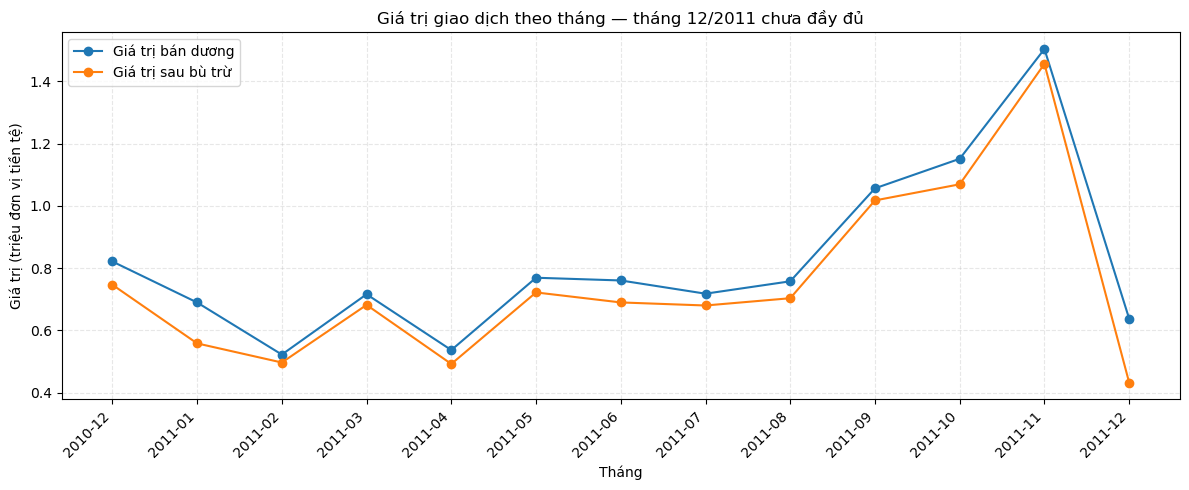

In [8]:
monthly_positive = retail_sales.groupby(
    retail_sales["InvoiceDate"].dt.to_period("M")
)["SalesValue"].sum()

monthly_signed = retail_signed.groupby(
    retail_signed["InvoiceDate"].dt.to_period("M")
)["SalesValue"].sum()

monthly_summary = pd.DataFrame({
    "Giá trị bán dương": monthly_positive,
    "Giá trị sau bù trừ": monthly_signed
}).sort_index()

display(monthly_summary.round(2))

fig, ax = plt.subplots(figsize=(12, 5))

x = range(len(monthly_summary))
month_labels = monthly_summary.index.astype(str)

for column in monthly_summary.columns:
    ax.plot(
        x,
        monthly_summary[column] / 1_000_000,
        marker="o",
        label=column
    )

ax.set_xticks(list(x))
ax.set_xticklabels(month_labels, rotation=45, ha="right")
ax.set_title("Giá trị giao dịch theo tháng — tháng 12/2011 chưa đầy đủ")
ax.set_xlabel("Tháng")
ax.set_ylabel("Giá trị (triệu đơn vị tiền tệ)")
ax.legend()
ax.grid(linestyle="--", alpha=0.3)

fig.tight_layout()
plt.show()

### 8. Giá trị bán dương theo quốc gia

Cộng SalesValue theo Country trên retail_sales.
Chỉ số bao gồm các dòng bán dương đã chọn, chưa khấu trừ
giao dịch hủy và vẫn bao gồm phí hoặc điều chỉnh.

,Giá trị bán dương,Tỷ lệ (%)
Country,,
United Kingdom,9001744.09,84.59
Netherlands,285446.34,2.68
EIRE,283140.52,2.66
Germany,228678.40,2.15
France,209625.37,1.97
Australia,138453.81,1.30
Spain,61558.56,0.58
Switzerland,57067.60,0.54
Belgium,41196.34,0.39


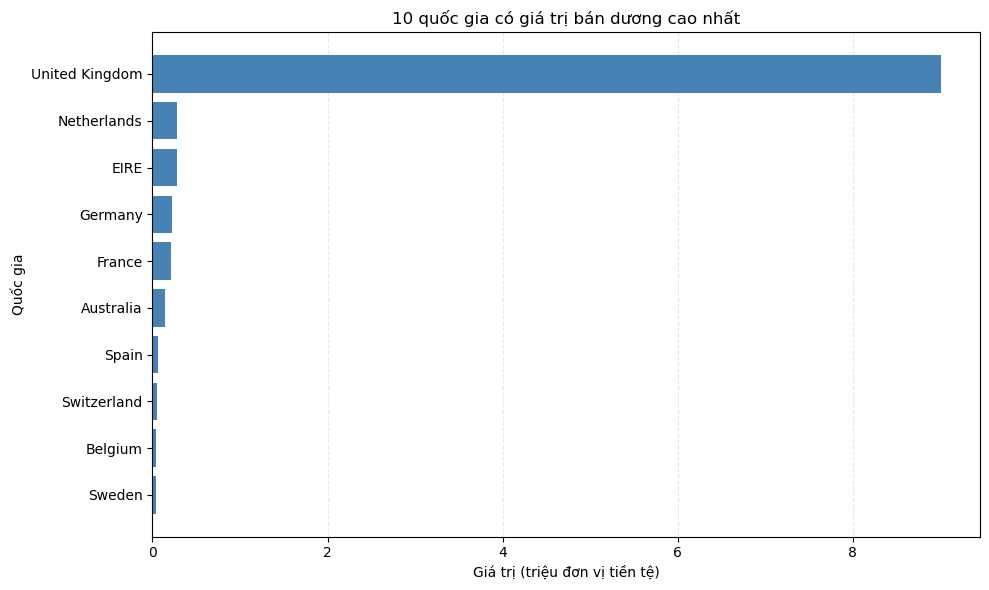

In [9]:
country_sales = (
    retail_sales.groupby("Country")["SalesValue"]
    .sum()
    .sort_values(ascending=False)
)

country_summary = country_sales.to_frame("Giá trị bán dương")
country_summary["Tỷ lệ (%)"] = (
    country_sales / country_sales.sum() * 100
)

display(country_summary.head(10).round(2))

top10_countries = country_sales.head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top10_countries.index,
    top10_countries.values / 1_000_000,
    color="steelblue"
)

ax.set_title("10 quốc gia có giá trị bán dương cao nhất")
ax.set_xlabel("Giá trị (triệu đơn vị tiền tệ)")
ax.set_ylabel("Quốc gia")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Giá trị bán dương của các quốc gia ngoài United Kingdom

Hiển thị 10 quốc gia có giá trị bán dương cao nhất sau khi
loại United Kingdom khỏi bảng xếp hạng, giúp quan sát
rõ hơn sự khác biệt giữa các quốc gia còn lại.

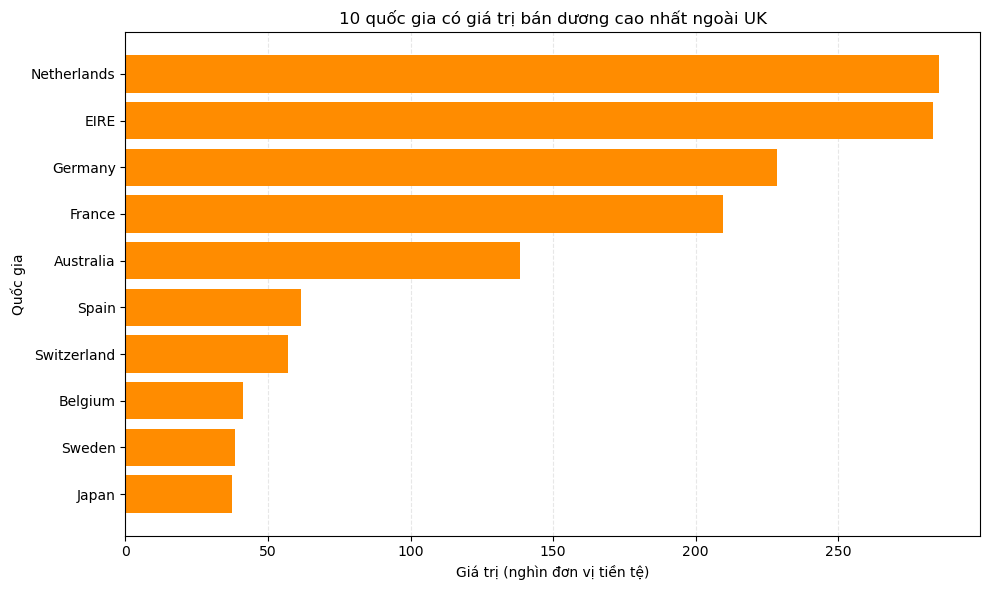

In [10]:
top10_non_uk = (
    country_sales.drop(index="United Kingdom")
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top10_non_uk.index,
    top10_non_uk.values / 1_000,
    color="darkorange"
)

ax.set_title("10 quốc gia có giá trị bán dương cao nhất ngoài UK")
ax.set_xlabel("Giá trị (nghìn đơn vị tiền tệ)")
ax.set_ylabel("Quốc gia")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### 9. Phân bố giá trị các hóa đơn bán dương

Cộng SalesValue theo InvoiceNo trên retail_sales.
Sử dụng thang log ở trục giá trị để quan sát phân bố có đuôi dài,
giữ toàn bộ hóa đơn và không loại các giá trị lớn.

Giá trị hóa đơn ở đây chưa khấu trừ các dòng hủy tương ứng.

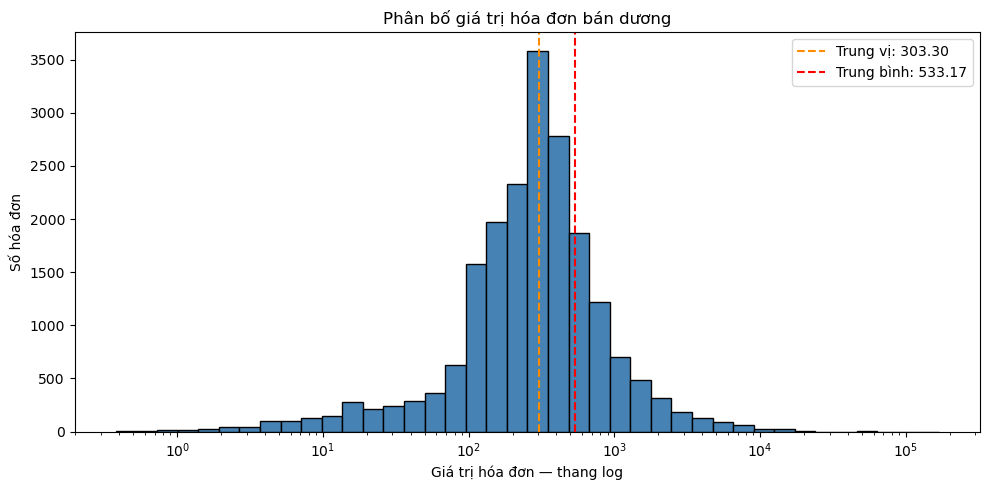

In [11]:
import numpy as np

# Các khoảng chia đều trên thang log
log_bins = np.geomspace(
    invoice_values.min(),
    invoice_values.max(),
    41
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    invoice_values,
    bins=log_bins,
    color="steelblue",
    edgecolor="black"
)

ax.set_xscale("log")
ax.axvline(
    invoice_values.median(),
    color="darkorange",
    linestyle="--",
    label=f"Trung vị: {invoice_values.median():,.2f}"
)
ax.axvline(
    invoice_values.mean(),
    color="red",
    linestyle="--",
    label=f"Trung bình: {invoice_values.mean():,.2f}"
)

ax.set_title("Phân bố giá trị hóa đơn bán dương")
ax.set_xlabel("Giá trị hóa đơn — thang log")
ax.set_ylabel("Số hóa đơn")
ax.legend()

fig.tight_layout()
plt.show()

### 10. Các mã hàng có giá trị bán dương cao nhất

Cộng SalesValue theo StockCode trên retail_sales.
Giữ nguyên các mã hàng, bao gồm cả mã phí hoặc điều chỉnh.

Bảng xếp hạng chưa khấu trừ các dòng hủy tương ứng,
nên không được diễn giải là xếp hạng sản phẩm theo doanh thu thuần.

,Description,Quantity,InvoiceCount,SalesValue
StockCode,,,,
DOT,DOTCOM POSTAGE,706,706,206248.77
22423,REGENCY CAKESTAND 3 TIER,13851,1988,174156.54
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,1,168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,2198,104462.75
47566,PARTY BUNTING,18283,1685,99445.23
85099B,JUMBO BAG RED RETROSPOT,48371,2089,94159.81
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,247,81700.92
POST,POSTAGE,3150,1126,78101.88
M,Manual,6984,289,77750.27


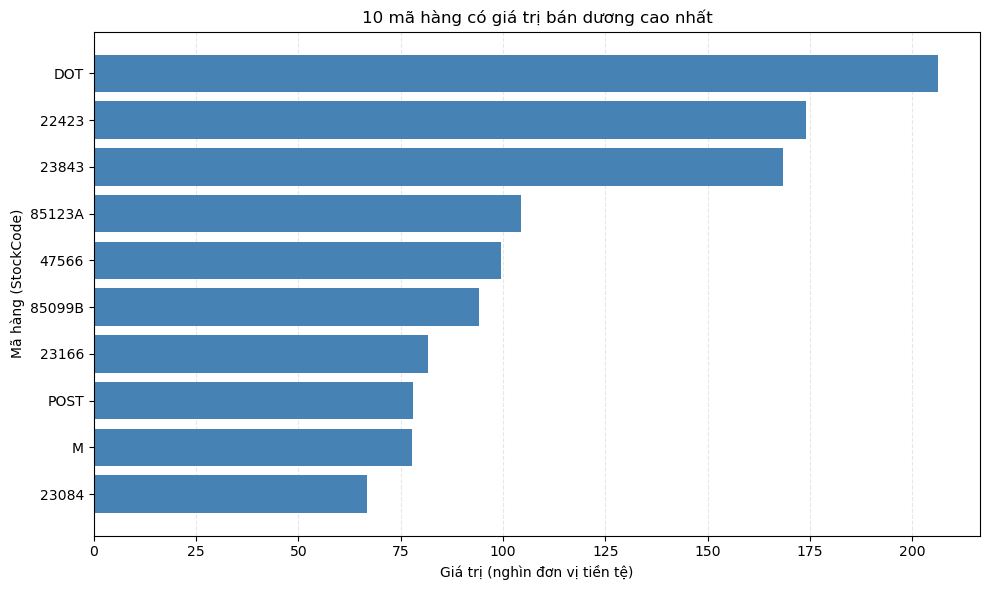

In [12]:
item_summary = (
    retail_sales.groupby("StockCode")
    .agg(
        SalesValue=("SalesValue", "sum"),
        Quantity=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique")
    )
    .sort_values("SalesValue", ascending=False)
)

# Chọn mô tả xuất hiện nhiều nhất cho mỗi mã
item_descriptions = (
    retail_sales.groupby("StockCode")["Description"]
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else "")
)

item_summary["Description"] = item_descriptions
top10_items = item_summary.head(10)

display(
    top10_items[
        ["Description", "Quantity", "InvoiceCount", "SalesValue"]
    ].round(2)
)

plot_items = top10_items.sort_values("SalesValue")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    plot_items.index.astype(str),
    plot_items["SalesValue"] / 1_000,
    color="steelblue"
)

ax.set_title("10 mã hàng có giá trị bán dương cao nhất")
ax.set_xlabel("Giá trị (nghìn đơn vị tiền tệ)")
ax.set_ylabel("Mã hàng (StockCode)")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Đối chiếu các mã hàng đứng đầu sau khi bù trừ dòng âm

Giữ danh sách 10 mã đứng đầu theo giá trị bán dương và
đối chiếu với tổng giá trị có dấu của cùng mã trong retail_signed.

Bảng này không phải bảng xếp hạng mới sau bù trừ.

In [13]:
signed_item_values = retail_signed.groupby(
    retail_signed["StockCode"].astype("string")
)["SalesValue"].sum()

item_comparison = top10_items[["Description", "SalesValue"]].copy()

item_comparison = item_comparison.rename(
    columns={"SalesValue": "Giá trị bán dương"}
)

item_comparison["Giá trị sau bù trừ"] = (
    signed_item_values.reindex(item_comparison.index)
)

item_comparison["Chênh lệch do dòng âm"] = (
    item_comparison["Giá trị sau bù trừ"]
    - item_comparison["Giá trị bán dương"]
)

display(item_comparison.round(2))

,Description,Giá trị bán dương,Giá trị sau bù trừ,Chênh lệch do dòng âm
StockCode,,,,
DOT,DOTCOM POSTAGE,206248.77,206245.48,-3.29
22423,REGENCY CAKESTAND 3 TIER,174156.54,164459.49,-9697.05
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,0.00,-168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,97838.45,-6624.30
47566,PARTY BUNTING,99445.23,98243.88,-1201.35
85099B,JUMBO BAG RED RETROSPOT,94159.81,92175.79,-1984.02
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,4221.28,-77479.64
POST,POSTAGE,78101.88,66230.64,-11871.24
M,Manual,77750.27,-69034.19,-146784.46


### 11. Tổng hợp giao dịch theo khách hàng có mã định danh

Chỉ sử dụng các dòng trong retail_sales có CustomerID.
Các dòng thiếu CustomerID vẫn được giữ trong phân tích
theo tháng và quốc gia.

Tính số hóa đơn và tổng giá trị bán dương của từng khách hàng.
Giá trị này chưa khấu trừ dòng hủy, vẫn bao gồm phí hoặc điều chỉnh.
Không đánh giá khách hàng chỉ dựa trên tổng giá trị bán dương.

Số dòng có CustomerID: 392,692
Số khách hàng: 4,338
Khách hàng có ít nhất 2 hóa đơn: 2,845
Tỷ lệ có ít nhất 2 hóa đơn: 65.58%


,InvoiceCount,SalesValue
CustomerID,,
14646,73,280206.02
18102,60,259657.30
17450,46,194390.79
16446,2,168472.50
14911,201,143711.17
12415,21,124914.53
14156,55,117210.08
17511,31,91062.38
16029,63,80850.84


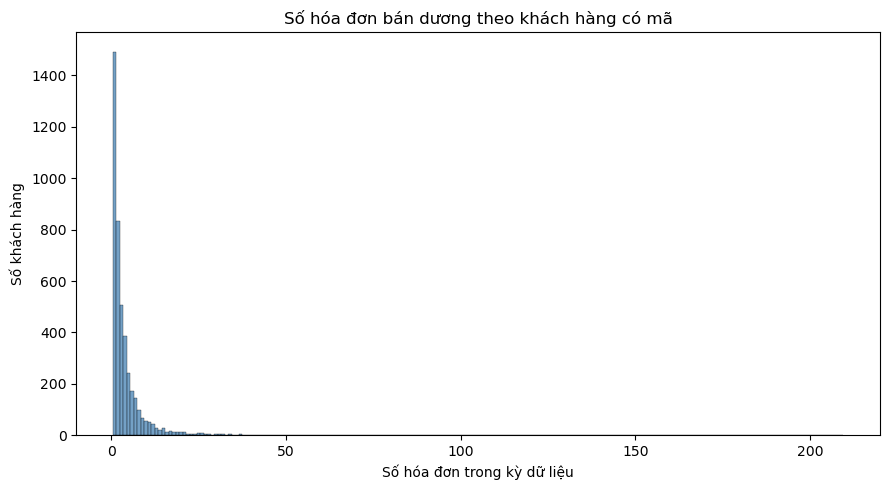

In [14]:
retail_customers = retail_sales.dropna(
    subset=["CustomerID"]
).copy()

# CustomerID là mã định danh
retail_customers["CustomerID"] = (
    retail_customers["CustomerID"].astype("int64").astype("string")
)

customer_summary = (
    retail_customers.groupby("CustomerID")
    .agg(
        InvoiceCount=("InvoiceNo", "nunique"),
        SalesValue=("SalesValue", "sum")
    )
    .sort_values("SalesValue", ascending=False)
)

print("Số dòng có CustomerID:", f"{len(retail_customers):,}")
print("Số khách hàng:", f"{len(customer_summary):,}")

repeat_count = (customer_summary["InvoiceCount"] >= 2).sum()

print("Khách hàng có ít nhất 2 hóa đơn:", f"{repeat_count:,}")
print(
    "Tỷ lệ có ít nhất 2 hóa đơn:",
    f"{repeat_count / len(customer_summary):.2%}"
)

display(customer_summary.head(10).round(2))

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    customer_summary["InvoiceCount"],
    discrete=True,
    color="steelblue",
    ax=ax
)

ax.set_title("Số hóa đơn bán dương theo khách hàng có mã")
ax.set_xlabel("Số hóa đơn trong kỳ dữ liệu")
ax.set_ylabel("Số khách hàng")

fig.tight_layout()
plt.show()

### 12. Nhận xét và giới hạn của phân tích

- Dữ liệu gốc gồm 541.909 dòng và 8 cột, ghi nhận từ
  01/12/2010 đến 09/12/2011. Mỗi dòng là một mục hàng,
  không phải một hóa đơn riêng biệt.
- CustomerID thiếu khoảng 24,93% trong dữ liệu gốc.
  Các dòng này được giữ khi phân tích theo thời gian và quốc gia,
  nhưng không dùng cho phân tích theo khách hàng.
- Loại 5.268 dòng trùng hoàn toàn theo giả định tránh đếm lặp.
  Sau khi chọn các dòng không thuộc hóa đơn hủy, có số lượng
  và đơn giá dương, còn 524.878 dòng với 19.960 hóa đơn.
- Tổng giá trị bán dương là 10.642.110,80. Khi tính thêm các
  dòng số lượng âm có đơn giá dương trên dữ liệu đã bỏ trùng,
  tổng giá trị sau bù trừ là 9.748.131,07.
- Hai giao dịch bán lớn nhất đều có dòng hủy khớp mã hàng,
  khách hàng, đơn giá và số lượng trái dấu. Tổng giá trị
  245.653,20 của hai dòng bán được bù trừ hoàn toàn.
- Dữ liệu có các mã phí và điều chỉnh như DOT, POST,
  AMAZONFEE và M. Các tổng giá trị chưa được coi là
  doanh thu thuần từ sản phẩm.
- Giá trị giao dịch tăng liên tiếp từ tháng 8 đến tháng 11/2011.
  Tháng 11 cao nhất ở cả giá trị bán dương và giá trị sau bù trừ.
  Tháng 12/2011 chỉ có dữ liệu đến ngày 9, nên mức giảm
  không đủ căn cứ để kết luận hoạt động bán hàng suy giảm.
- United Kingdom chiếm khoảng 84,59% giá trị bán dương.
  Trong các quốc gia ngoài UK, Netherlands và EIRE đứng đầu.
- Giá trị hóa đơn bán dương có trung bình 533,17 và trung vị
  303,30. Một số hóa đơn lớn kéo trung bình lên; biểu đồ
  sử dụng thang log để thể hiện toàn bộ phạm vi giá trị.
- Mã DOT đứng đầu theo giá trị bán dương nhưng là phí vận chuyển.
  Mã 23843 có giá trị sau bù trừ bằng 0; mã 23166 giảm còn
  4.221,28. Bảng xếp hạng dòng dương chịu ảnh hưởng của
  các giao dịch hủy và không phản ánh doanh thu thuần.
- Có 4.338 khách hàng được định danh trong dữ liệu bán dương;
  2.845 người có ít nhất hai hóa đơn, tương ứng 65,58%.
  Đây là tỷ lệ trong nhóm có mã và trong kỳ dữ liệu,
  chưa phải tỷ lệ giữ chân khách hàng.
- Các kết quả phụ thuộc vào phạm vi dữ liệu và giả định
  làm sạch. Chưa xác minh đầy đủ từng dòng trùng, phân loại
  toàn bộ mã phí hoặc liên kết mọi giao dịch hủy với giao dịch bán.